## 📌 SECTION 1: Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
from sklearn.datasets import load_iris

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Train-Test Split & Cross Validation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# ✅ Three Naive Bayes Models
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


---
## 📌 SECTION 2: Load Dataset

We will use two datasets:
- **Iris Dataset** → for Gaussian NB (continuous features)
- **Custom Student Dataset** → for all 3 NB variants with full preprocessing

### 2B. Custom Student Dataset (Simulated Messy Real-World Data)

In [ ]:
np.random.seed(42)
n = 200

data = {
    'age':          np.random.randint(18, 25, n).astype(float),
    'cgpa':         np.round(np.random.uniform(2.0, 4.0, n), 2),
    'attendance':   np.random.randint(50, 100, n).astype(float),
    'study_hours':  np.random.randint(1, 10, n).astype(float),
    'gender':       np.random.choice(['Male', 'Female', 'male', 'FEMALE', None], n),
    'department':   np.random.choice(['CS', 'EEE', 'BBA', 'English', None], n),
    'passed':       np.random.choice([0, 1], n, p=[0.3, 0.7])
}

df = pd.DataFrame(data)

# Inject missing values
for col in ['cgpa', 'attendance', 'study_hours']:
    df.loc[df.sample(frac=0.1).index, col] = np.nan

print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
df.head(10)

Shape: (200, 7)

Missing Values:
age             0
cgpa           20
attendance     20
study_hours    20
gender         41
department     39
passed          0
dtype: int64


,age,cgpa,attendance,study_hours,gender,department,passed
0,24.0,2.59,72.0,1.0,None,BBA,1
1,21.0,2.21,58.0,6.0,FEMALE,English,0
2,22.0,2.91,61.0,4.0,Female,EEE,1
3,24.0,2.44,50.0,1.0,FEMALE,None,1
4,20.0,NaN,50.0,7.0,Female,EEE,1
5,22.0,3.77,96.0,NaN,None,CS,1
6,22.0,2.65,83.0,4.0,Female,CS,0
7,24.0,2.24,81.0,4.0,male,English,0
8,19.0,2.71,97.0,6.0,male,BBA,1
9,20.0,NaN,74.0,3.0,male,English,0


---
## 📌 SECTION 3: Exploratory Data Analysis (EDA)

In [ ]:
print(df.info())
print("\n")
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          200 non-null    float64
 1   cgpa         180 non-null    float64
 2   attendance   180 non-null    float64
 3   study_hours  180 non-null    float64
 4   gender       159 non-null    object 
 5   department   161 non-null    object 
 6   passed       200 non-null    int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 11.1+ KB
None


              age        cgpa  attendance  study_hours      passed
count  200.000000  180.000000  180.000000   180.000000  200.000000
mean    21.170000    2.986444   75.533333     4.750000    0.695000
std      2.002787    0.563104   14.295133     2.562896    0.461563
min     18.000000    2.000000   50.000000     1.000000    0.000000
25%     19.000000    2.537500   62.000000     3.000000    0.000000
50%     21.000000    2.905000   75.000000     

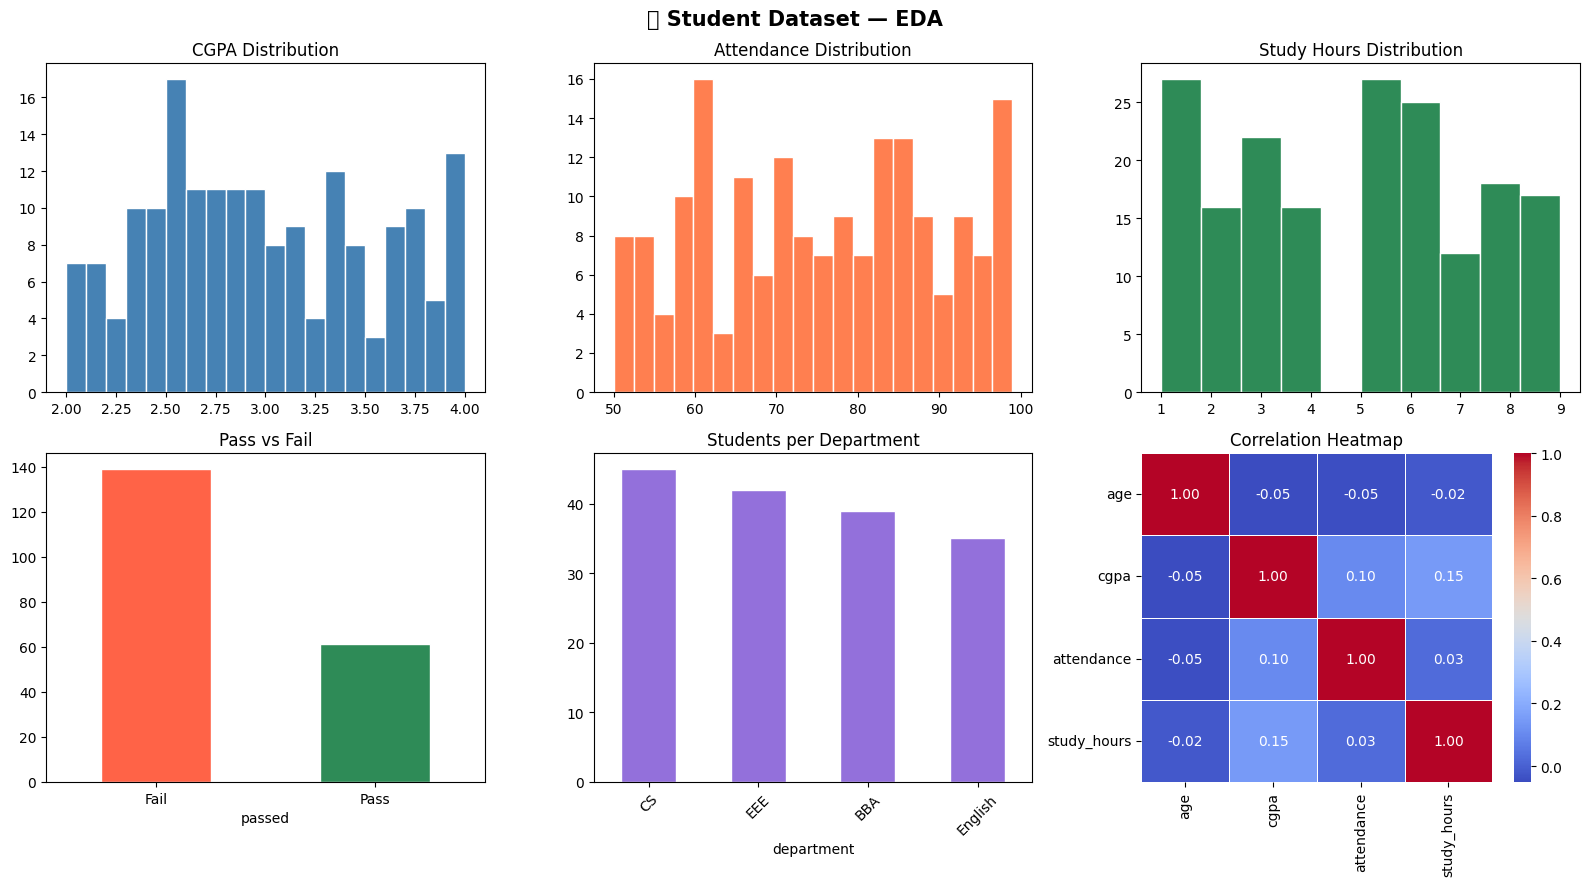

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('📊 Student Dataset — EDA', fontsize=15, fontweight='bold')

axes[0,0].hist(df['cgpa'].dropna(), bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_title('CGPA Distribution')

axes[0,1].hist(df['attendance'].dropna(), bins=20, color='coral', edgecolor='white')
axes[0,1].set_title('Attendance Distribution')

axes[0,2].hist(df['study_hours'].dropna(), bins=10, color='seagreen', edgecolor='white')
axes[0,2].set_title('Study Hours Distribution')

df['passed'].value_counts().plot(kind='bar', ax=axes[1,0],
    color=['tomato','seagreen'], edgecolor='white')
axes[1,0].set_title('Pass vs Fail')
axes[1,0].set_xticklabels(['Fail','Pass'], rotation=0)

df['department'].value_counts().plot(kind='bar', ax=axes[1,1],
    color='mediumpurple', edgecolor='white')
axes[1,1].set_title('Students per Department')
axes[1,1].tick_params(axis='x', rotation=45)

numeric = df[['age','cgpa','attendance','study_hours']]
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=axes[1,2], linewidths=0.5)
axes[1,2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

---
## 📌 SECTION 4: Data Preprocessing

### Step 1 — Handle Missing Values

In [ ]:
df_clean = df.copy()

# Fill numeric columns with MEDIAN (robust to outliers)
for col in ['cgpa', 'attendance', 'study_hours']:
    median_val = df_clean[col].median()
    df_clean[col].fillna(median_val, inplace=True)
    print(f"{col}: filled missing with median = {median_val:.2f}")

# Fill categorical with MODE
df_clean['department'].fillna(df_clean['department'].mode()[0], inplace=True)
df_clean['gender'].fillna('Unknown', inplace=True)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

cgpa: filled missing with median = 2.91
attendance: filled missing with median = 75.00
study_hours: filled missing with median = 5.00

Missing values after cleaning:
age            0
cgpa           0
attendance     0
study_hours    0
gender         0
department     0
passed         0
dtype: int64


### Step 2 — Clean & Encode Categorical Columns

In [ ]:
# Fix inconsistent gender values: 'male', 'FEMALE', 'Male' → uniform
print("Before:", df_clean['gender'].unique())
df_clean['gender'] = df_clean['gender'].str.strip().str.title()
df_clean['gender'] = df_clean['gender'].map({'Male': 1, 'Female': 0, 'Unknown': -1})
print("After:", df_clean['gender'].unique())

# Label encode department
le = LabelEncoder()
df_clean['dept_encoded'] = le.fit_transform(df_clean['department'])
print("\nDepartment encoding:")
for i, cls in enumerate(le.classes_):
    print(f"  {cls} → {i}")

Before: ['Unknown' 'FEMALE' 'Female' 'male' 'Male']
After: [-1  0  1]

Department encoding:
  BBA → 0
  CS → 1
  EEE → 2
  English → 3


### Step 3 — Feature Scaling

> ⚠️ **Important Rule:** Split data FIRST, then scale — never scale before splitting!
>
> Scaling before split = **Data Leakage** (test info leaks into training)

In [ ]:
# Define features and target
features = ['age', 'cgpa', 'attendance', 'study_hours', 'gender', 'dept_encoded']
X = df_clean[features]
y = df_clean['passed']

# ✅ STEP 1: Split FIRST (stratified to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train class dist: {y_train.value_counts().to_dict()}")
print(f"Test  class dist: {y_test.value_counts().to_dict()}")

# ✅ STEP 2: Scale AFTER split — fit only on train!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_test_scaled  = scaler.transform(X_test)          # transform only

print("\n✅ Data split and scaled correctly — no leakage!")

Train: (160, 6)  |  Test: (40, 6)
Train class dist: {1: 111, 0: 49}
Test  class dist: {1: 28, 0: 12}

✅ Data split and scaled correctly — no leakage!


---
## 📌 SECTION 5: Naive Bayes Models

| Model | Best For | Feature Type |
|-------|----------|--------------|
| **GaussianNB** | Continuous numeric features | Real numbers (height, CGPA) |
| **MultinomialNB** | Count-based features | Word counts, frequencies |
| **BernoulliNB** | Binary features | 0/1 (yes/no, present/absent) |

---
### 5A. Gaussian Naive Bayes

> Assumes features follow a **Gaussian (Normal) distribution**.  
> Best for: CGPA, Attendance, Age — all continuous values.

        GAUSSIAN NAIVE BAYES RESULTS
Training Accuracy : 0.7125
Testing  Accuracy : 0.6750

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00        12
        Pass       0.69      0.96      0.81        28

    accuracy                           0.68        40
   macro avg       0.35      0.48      0.40        40
weighted avg       0.48      0.68      0.56        40



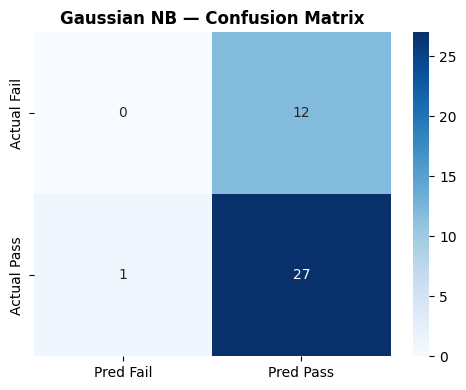

In [ ]:
# Train
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)

# Predict
y_pred_gnb = gnb.predict(X_test_scaled)

# Evaluate
print("=" * 45)
print("        GAUSSIAN NAIVE BAYES RESULTS")
print("=" * 45)
print(f"Training Accuracy : {accuracy_score(y_train, gnb.predict(X_train_scaled)):.4f}")
print(f"Testing  Accuracy : {accuracy_score(y_test, y_pred_gnb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gnb, target_names=['Fail','Pass']))

# Confusion Matrix
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
plt.figure(figsize=(5,4))
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Fail','Pred Pass'],
            yticklabels=['Actual Fail','Actual Pass'])
plt.title('Gaussian NB — Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

### 5B. Multinomial Naive Bayes

> Assumes features are **non-negative counts or frequencies**.  
> We use `MinMaxScaler` here to ensure values are ≥ 0 (MultinomialNB requires this).

      MULTINOMIAL NAIVE BAYES RESULTS
Training Accuracy : 0.6937
Testing  Accuracy : 0.7000

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00        12
        Pass       0.70      1.00      0.82        28

    accuracy                           0.70        40
   macro avg       0.35      0.50      0.41        40
weighted avg       0.49      0.70      0.58        40



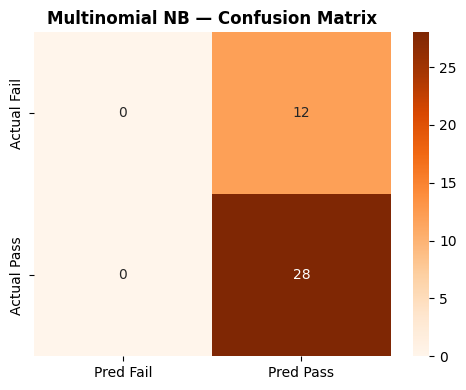

In [ ]:
# MultinomialNB requires non-negative features → use MinMaxScaler
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm  = mm_scaler.transform(X_test)

# Train
mnb = MultinomialNB()
mnb.fit(X_train_mm, y_train)

# Predict
y_pred_mnb = mnb.predict(X_test_mm)

# Evaluate
print("=" * 45)
print("      MULTINOMIAL NAIVE BAYES RESULTS")
print("=" * 45)
print(f"Training Accuracy : {accuracy_score(y_train, mnb.predict(X_train_mm)):.4f}")
print(f"Testing  Accuracy : {accuracy_score(y_test, y_pred_mnb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_mnb, target_names=['Fail','Pass']))

# Confusion Matrix
cm_mnb = confusion_matrix(y_test, y_pred_mnb)
plt.figure(figsize=(5,4))
sns.heatmap(cm_mnb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Pred Fail','Pred Pass'],
            yticklabels=['Actual Fail','Actual Pass'])
plt.title('Multinomial NB — Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

### 5C. Bernoulli Naive Bayes

> Assumes features are **binary (0 or 1)**.  
> We binarize our features using the mean as threshold: above mean → 1, below → 0.

Sample binarized row (0s and 1s only):
[0. 1. 1. 0. 0. 0.]

       BERNOULLI NAIVE BAYES RESULTS
Training Accuracy : 0.7000
Testing  Accuracy : 0.6750

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00        12
        Pass       0.69      0.96      0.81        28

    accuracy                           0.68        40
   macro avg       0.35      0.48      0.40        40
weighted avg       0.48      0.68      0.56        40



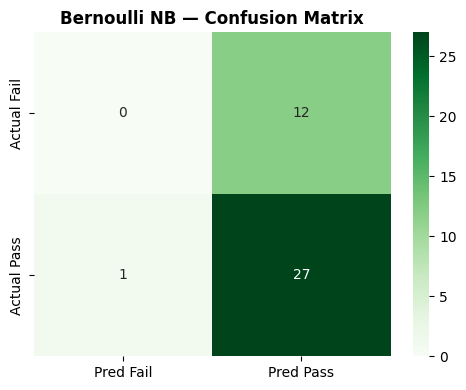

In [ ]:
# Binarize: values above mean = 1, below = 0
from sklearn.preprocessing import Binarizer

# We binarize the already-scaled data (threshold=0 for StandardScaler output)
binarizer = Binarizer(threshold=0)
X_train_bin = binarizer.fit_transform(X_train_scaled)
X_test_bin  = binarizer.transform(X_test_scaled)

print("Sample binarized row (0s and 1s only):")
print(X_train_bin[0])

# Train
bnb = BernoulliNB()
bnb.fit(X_train_bin, y_train)

# Predict
y_pred_bnb = bnb.predict(X_test_bin)

# Evaluate
print("\n" + "=" * 45)
print("       BERNOULLI NAIVE BAYES RESULTS")
print("=" * 45)
print(f"Training Accuracy : {accuracy_score(y_train, bnb.predict(X_train_bin)):.4f}")
print(f"Testing  Accuracy : {accuracy_score(y_test, y_pred_bnb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_bnb, target_names=['Fail','Pass']))

# Confusion Matrix
cm_bnb = confusion_matrix(y_test, y_pred_bnb)
plt.figure(figsize=(5,4))
sns.heatmap(cm_bnb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pred Fail','Pred Pass'],
            yticklabels=['Actual Fail','Actual Pass'])
plt.title('Bernoulli NB — Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
import joblib
from google.colab import files
filename = "Student dataset[ISHU].joblib"

# Save the Gaussian Naive Bayes model
joblib.dump(gnb, filename)
files.download(filename)

print("please check Browser download🪲")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

please check Browser download🪲
